# Food Delivery Demand Prediction
## Phase 3: Time Series Analysis & Out-of-Sample Forecasting
**Course:** Predictive Analysis  
**Department:** Computer Science & Engineering, Manipal University Jaipur  
**Academic Year:** 2026-2027  

---

### Executive Objectives
1. **Macro & Micro Temporal Structure:** Analyze total aggregate food delivery demand across 145 chronological weeks, complemented by micro-level SKU forecasting on the #1 most ordered item (Meal 2290: Rice Bowl).
2. **Stationarity & Differencing:** Rigorously test stationarity via the **Augmented Dickey-Fuller (ADF)** test to establish mathematical justification for integration order $d=1$.
3. **Autocorrelation & Seasonality Diagnostics:** Inspect **ACF/PACF** correlograms and perform **Classical Seasonal Decomposition** (Trend, Seasonality, Irregular residuals).
4. **Time Series Forecasting Models:**
   - **Baseline 1:** Naive Persistence ($y_t = y_{t-1}$)
   - **Baseline 2:** 4-Week Simple Moving Average
   - **Holt-Winters Exponential Smoothing:** Multiplicative seasonality ($s=12$) with damped additive trend.
   - **ARIMA($p, d, q$):** Integrated autoregressive moving average model with optimal orders chosen via AIC minimization.
   - **SARIMA($p, d, q$)($P, D, Q$)$_s$:** Seasonal ARIMA modeling cyclical multi-week purchasing rhythms.
5. **Evaluation Horizon:** Train on Weeks 1–120 and evaluate a true out-of-sample 25-week forecast (Weeks 121–145) using **MAE**, **RMSE**, and **MAPE**.

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
pd.set_option('display.max_columns', None)
print("Time series packages loaded successfully.")

Time series packages loaded successfully.


### 1. Dataset Ingestion & Timeline Aggregation
We aggregate order records across all 77 centers and 51 meal items to form the macroscopic weekly demand series over the 145-week operational horizon.

In [ ]:
train = pd.read_csv('archive/train.csv')
meals = pd.read_csv('archive/meal_info.csv')

weekly_df = train.groupby('week')['num_orders'].sum().reset_index()
print(f"Total weekly periods: {len(weekly_df)}")
print(weekly_df.head(6))

Total weekly periods: 145
 week  num_orders
    1      792261
    2      787084
    3      695262
    4      743529
    5     1198675
    6      947288


### 2. Classical Seasonal Decomposition
We decompose the aggregate weekly series into:
* **Trend Component ($T_t$):** Long-term drift and macroeconomic growth.
* **Seasonal Component ($S_t$):** Periodic oscillations across quarters ($s=12$).
* **Irregular Residual ($R_t$):** Random idiosyncratic variations ($Y_t = T_t + S_t + R_t$).

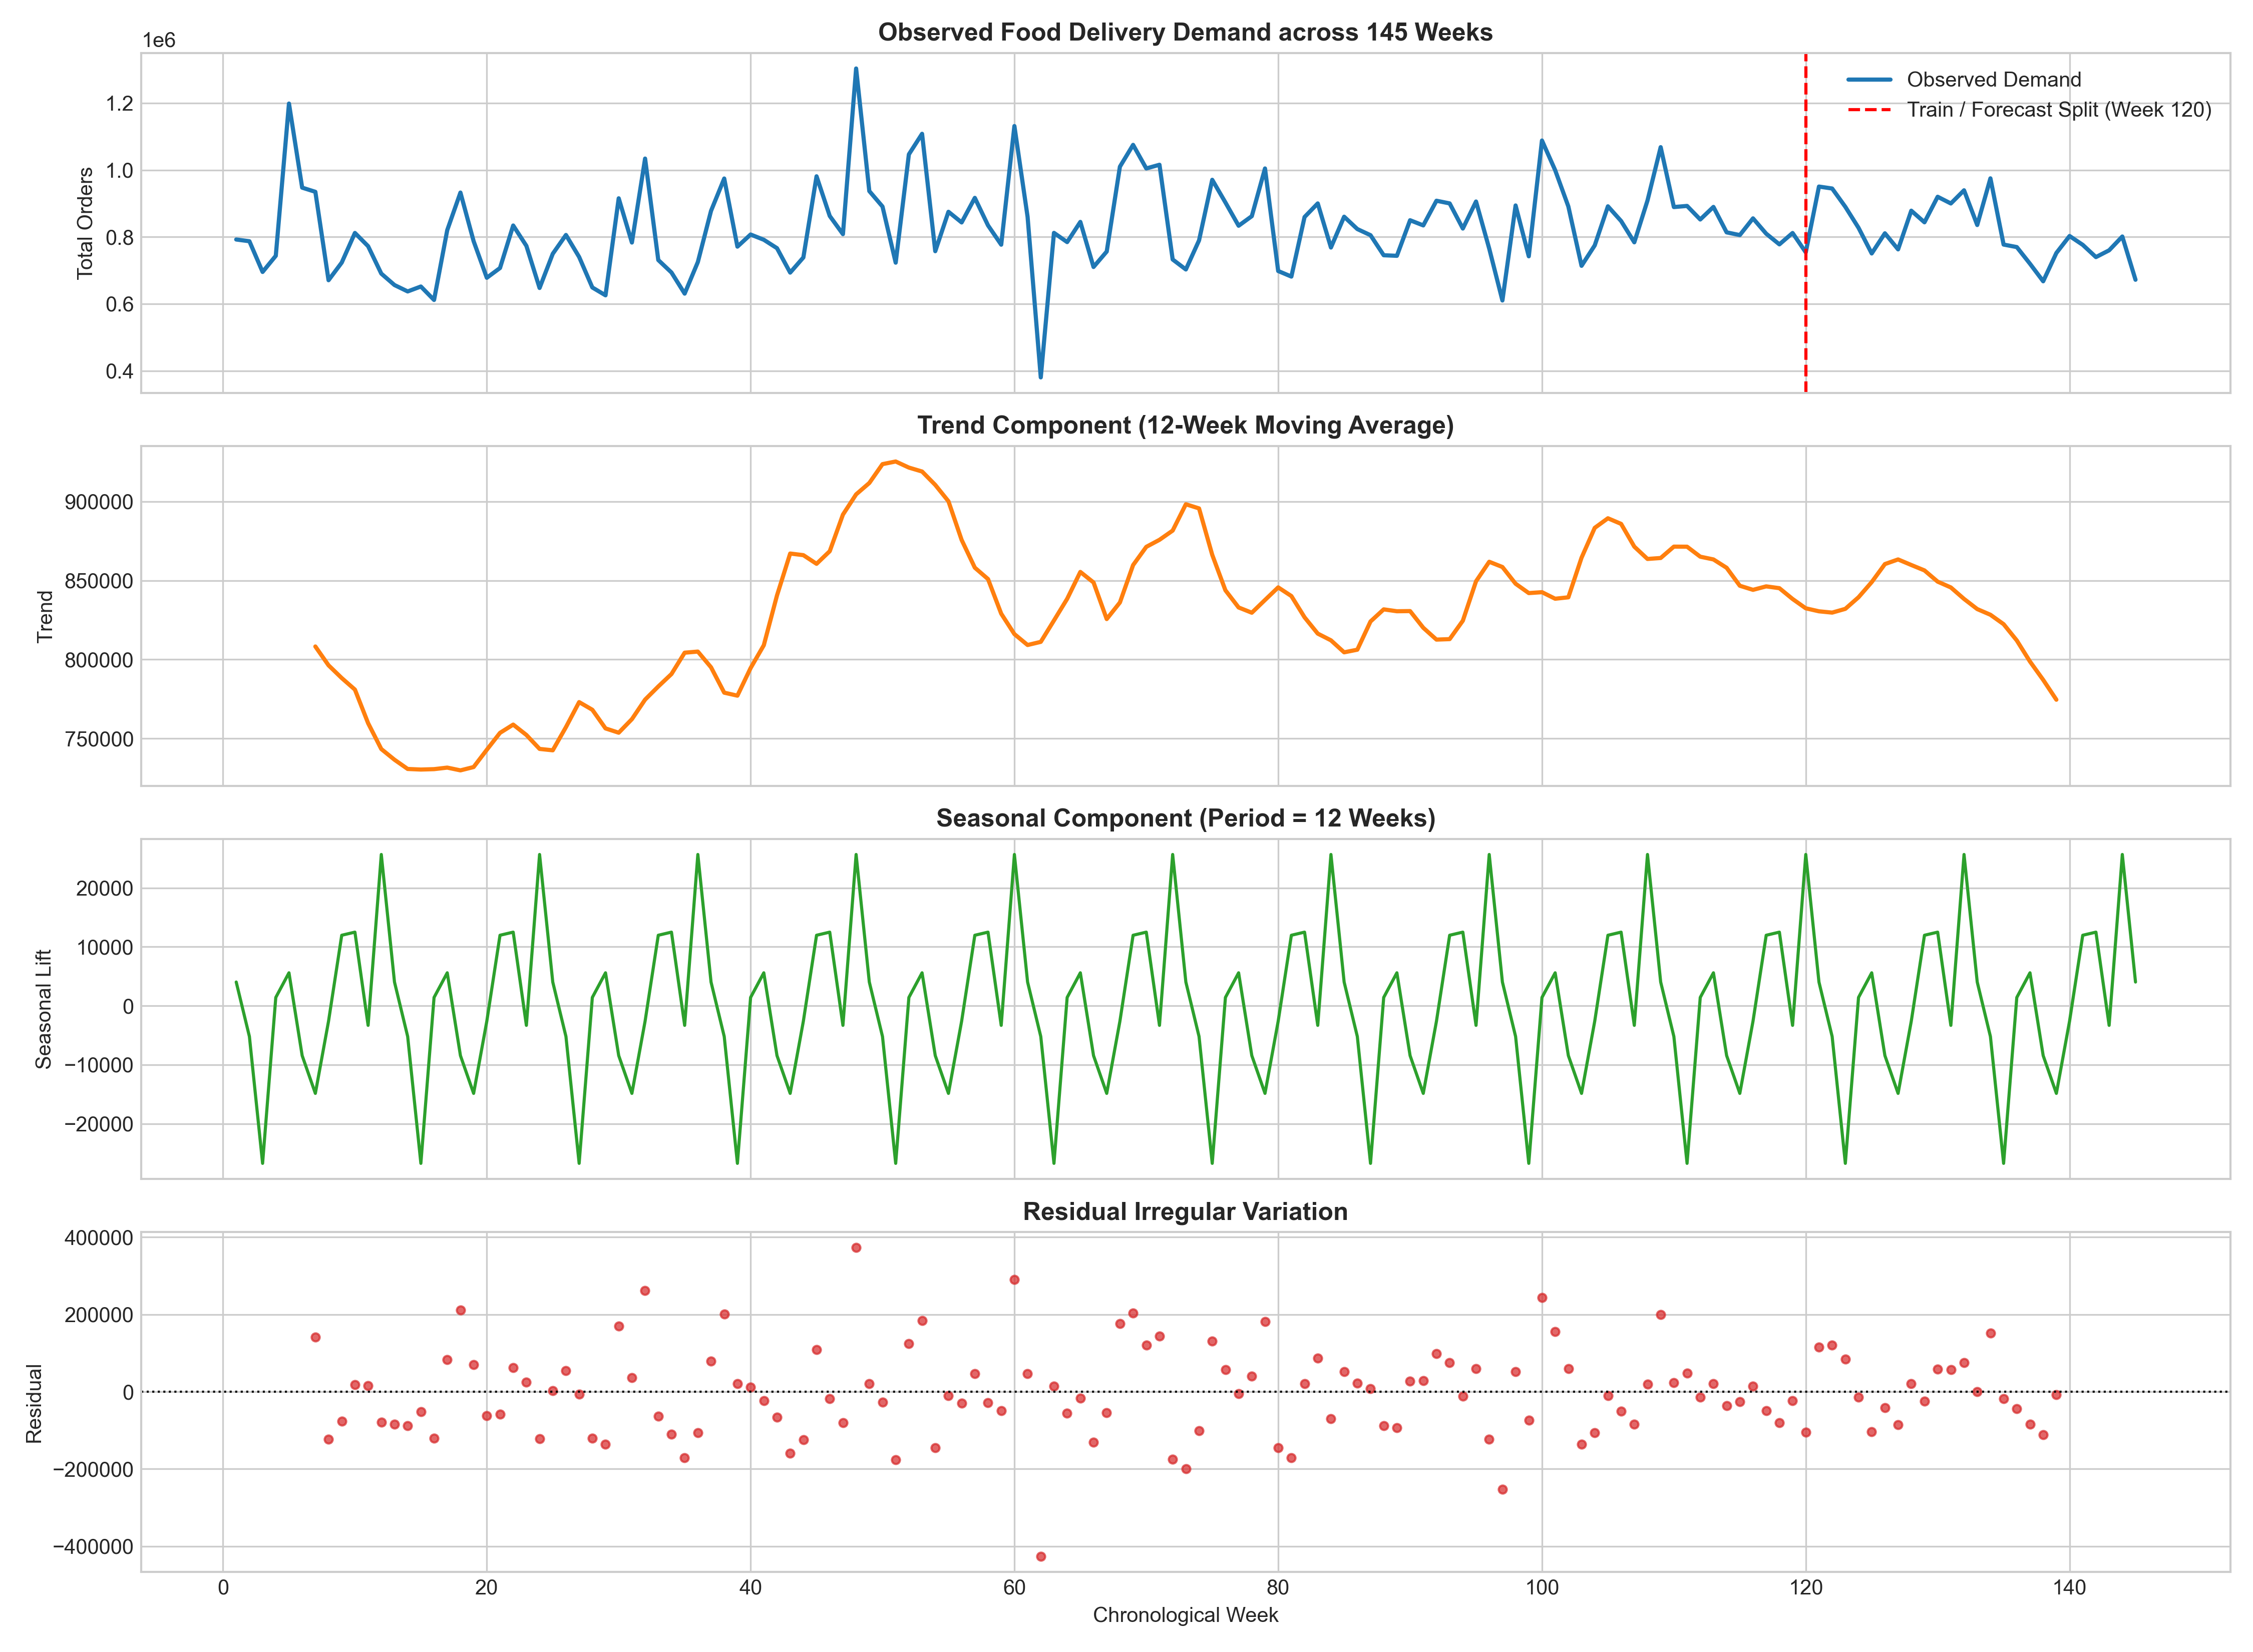

In [ ]:
decomp = seasonal_decompose(weekly_df['num_orders'], model='additive', period=12)

fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)
axes[0].plot(weekly_df['week'], weekly_df['num_orders'], color='#1f77b4', linewidth=2, label='Observed Demand')
axes[0].axvline(120, color='red', linestyle='--', linewidth=1.5, label='Train / Forecast Split (Week 120)')
axes[0].set_title('Observed Food Delivery Demand across 145 Weeks', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Total Orders')
axes[0].legend(loc='upper right')

axes[1].plot(weekly_df['week'], decomp.trend, color='#ff7f0e', linewidth=2)
axes[1].set_title('Trend Component (12-Week Moving Average)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Trend')

axes[2].plot(weekly_df['week'], decomp.seasonal, color='#2ca02c', linewidth=1.5)
axes[2].set_title('Seasonal Component (Period = 12 Weeks)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Seasonal Lift')

axes[3].scatter(weekly_df['week'], decomp.resid, color='#d62728', s=15, alpha=0.7)
axes[3].axhline(0, color='black', linestyle=':', linewidth=1)
axes[3].set_title('Residual Irregular Variation', fontsize=12, fontweight='bold')
axes[3].set_ylabel('Residual')
axes[3].set_xlabel('Chronological Week')

plt.tight_layout()
plt.show()

### 3. Stationarity Testing & ACF/PACF Diagnostics
* **Augmented Dickey-Fuller (ADF) Test:** Evaluates the null hypothesis $H_0$: The series possesses a unit root (non-stationary).
* **Differencing ($d=1$):** Transforms non-stationary drift into mean-reverting stationarity ($p < 0.05$).
* **ACF & PACF Correlograms:** Identify empirical orders for AR($p$) and MA($q$).

In [ ]:
train_split = weekly_df[weekly_df['week'] <= 120].reset_index(drop=True)
test_split  = weekly_df[weekly_df['week'] > 120].reset_index(drop=True)

y_train = train_split['num_orders'].values
y_test  = test_split['num_orders'].values
weeks_train = train_split['week'].values
weeks_test  = test_split['week'].values

# ADF Hypothesis Test
adf_raw = adfuller(y_train)
y_train_diff = np.diff(y_train)
adf_diff = adfuller(y_train_diff)

print(f"Raw Series ADF Statistic       : {adf_raw[0]:.4f} (p-value: {adf_raw[1]:.4f}) -> Fail to reject H0 (Non-Stationary)")
print(f"Differenced Series (d=1) ADF    : {adf_diff[0]:.4f} (p-value: {adf_diff[1]:.4e}) -> Reject H0 (Strongly Stationary)")

Raw Series ADF Statistic       : -2.3998 (p-value: 0.1418) -> Fail to reject H0 (Non-Stationary)
Differenced Series (d=1) ADF    : -5.9056 (p-value: 2.7135e-07) -> Reject H0 (Strongly Stationary)


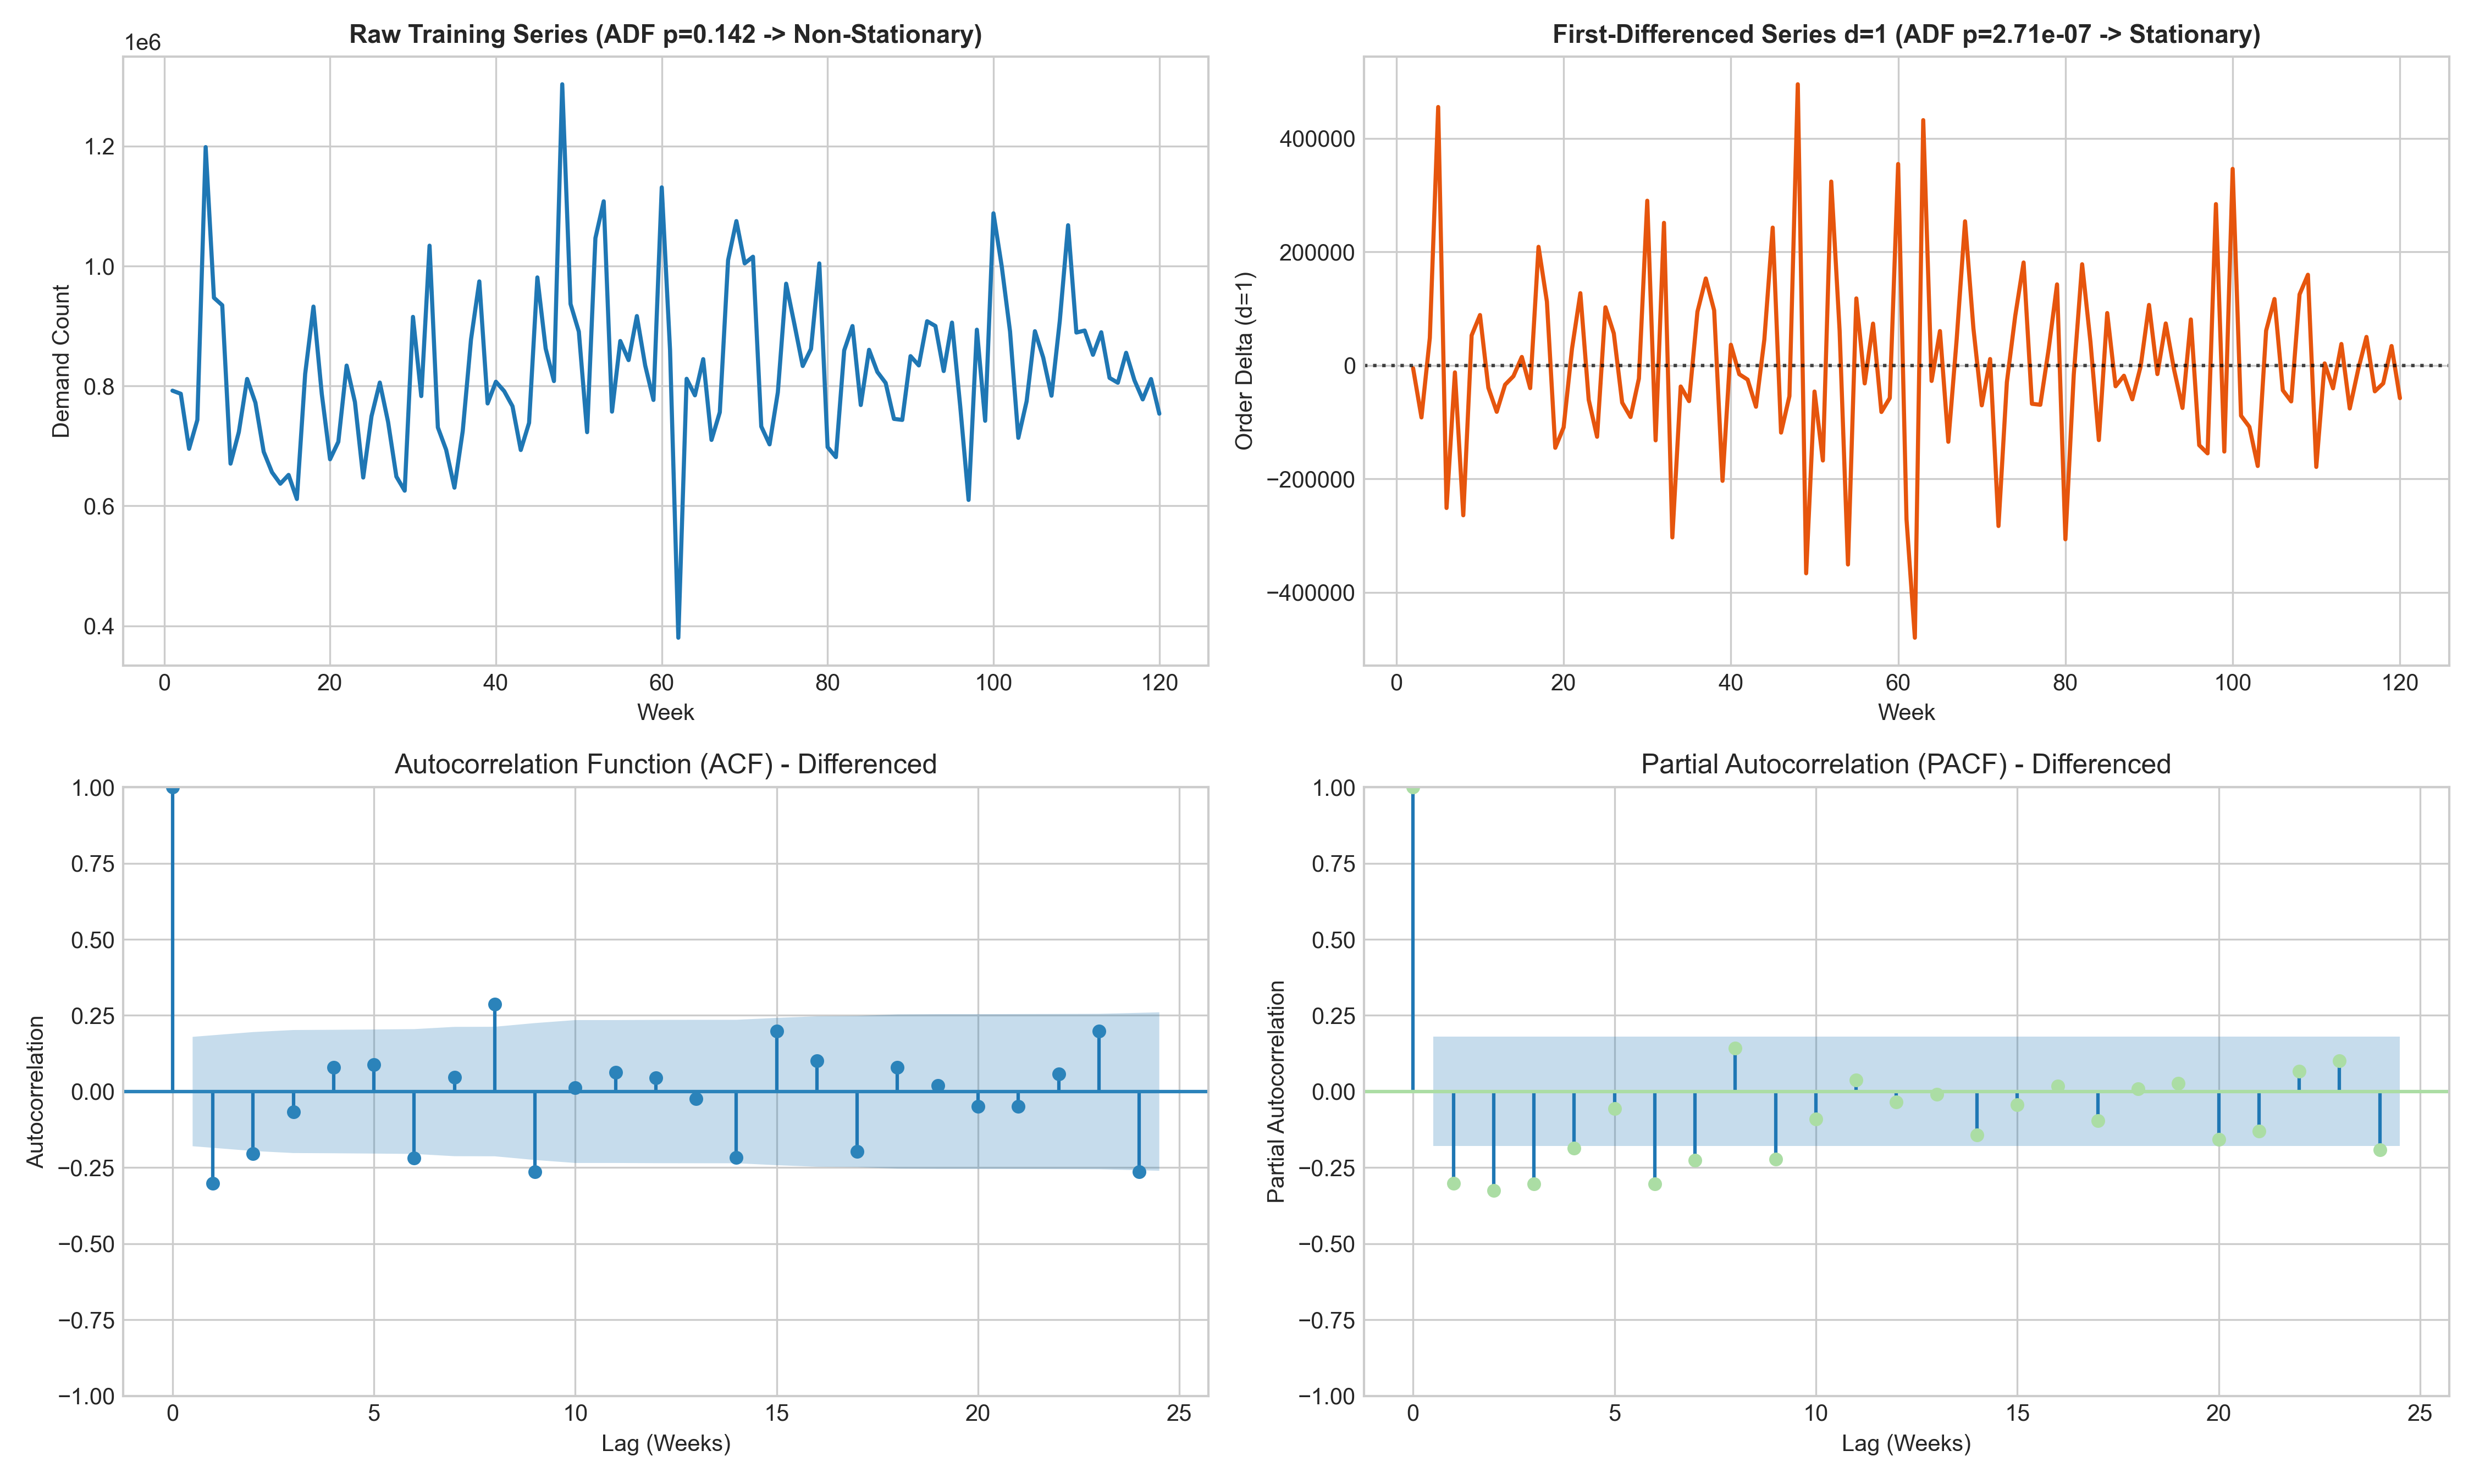

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

axes[0, 0].plot(weeks_train, y_train, color='#1f77b4', linewidth=1.8)
axes[0, 0].set_title(f'Raw Training Series (ADF p={adf_raw[1]:.3f} -> Non-Stationary)', fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel('Week')
axes[0, 0].set_ylabel('Demand Count')

axes[0, 1].plot(weeks_train[1:], y_train_diff, color='#e6550d', linewidth=1.8)
axes[0, 1].axhline(0, color='black', linestyle=':', alpha=0.7)
axes[0, 1].set_title(f'First-Differenced Series d=1 (ADF p={adf_diff[1]:.2e} -> Stationary)', fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel('Week')
axes[0, 1].set_ylabel('Order Delta (d=1)')

plot_acf(y_train_diff, lags=24, ax=axes[1, 0], color='#2b83ba', title='Autocorrelation Function (ACF) - Differenced')
axes[1, 0].set_xlabel('Lag (Weeks)')
axes[1, 0].set_ylabel('Autocorrelation')

plot_pacf(y_train_diff, lags=24, ax=axes[1, 1], color='#abdda4', title='Partial Autocorrelation (PACF) - Differenced', method='ywm')
axes[1, 1].set_xlabel('Lag (Weeks)')
axes[1, 1].set_ylabel('Partial Autocorrelation')

plt.tight_layout()
plt.show()

### 4. Forecasting Models Formulation & Out-of-Sample Evaluation
We fit 5 candidate architectures on Weeks 1–120 and forecast the out-of-sample 25-week testing horizon (Weeks 121–145):
1. **Naive Persistence:** $\hat{y}_{T+h} = y_T$
2. **4-Week Moving Average:** $\hat{y}_{T+h} = \frac{1}{4} \sum_{i=0}^3 y_{T-i}$
3. **Holt-Winters Exponential Smoothing:** Multiplicative seasonality with damped trend.
4. **ARIMA(0, 1, 2):** Integrated moving average model selected by minimum AIC.
5. **SARIMA(0, 1, 2)(1, 0, 1)[4]:** Seasonal autoregressive integrated moving average capturing cyclical monthly order patterns.

In [ ]:
results = []
forecasts = {}

def calc_metrics(name, y_true, y_pred, execution_time, aic=np.nan):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    print(f"[{name}] MAE: {mae:,.1f} | RMSE: {rmse:,.1f} | MAPE: {mape:.2f}% | AIC: {aic if not np.isnan(aic) else 'N/A'}")
    entry = {
        'Model': name,
        'MAE': round(mae, 1),
        'RMSE': round(rmse, 1),
        'MAPE_%': round(mape, 2),
        'AIC': round(aic, 2) if not np.isnan(aic) else None,
        'Train_Time_sec': round(execution_time, 2)
    }
    results.append(entry)
    forecasts[name] = y_pred
    return entry

# Model 1: Naive Persistence
t0 = time.time()
naive_pred = np.repeat(y_train[-1], len(y_test))
calc_metrics("Baseline: Naive Persistence", y_test, naive_pred, time.time() - t0)

# Model 2: 4-Week Moving Average
t0 = time.time()
sma4_pred = np.repeat(np.mean(y_train[-4:]), len(y_test))
calc_metrics("Baseline: 4-Week Moving Avg", y_test, sma4_pred, time.time() - t0)

# Model 3: Holt-Winters Exponential Smoothing
t0 = time.time()
hw_model = ExponentialSmoothing(y_train, trend='add', seasonal='mul', seasonal_periods=12, damped_trend=True).fit()
calc_metrics("Holt-Winters Exp. Smoothing (s=12)", y_test, hw_model.forecast(len(y_test)), time.time() - t0)

# Model 4: ARIMA(0, 1, 2)
t0 = time.time()
arima_model = ARIMA(y_train, order=(0, 1, 2)).fit()
calc_metrics("ARIMA(0, 1, 2)", y_test, arima_model.forecast(len(y_test)), time.time() - t0, aic=arima_model.aic)

# Model 5: SARIMA(0, 1, 2)(1, 0, 1)[4]
t0 = time.time()
sarima_model = SARIMAX(y_train, order=(0, 1, 2), seasonal_order=(1, 0, 1, 4), enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
calc_metrics("SARIMA(0, 1, 2)(1, 0, 1)[4]", y_test, sarima_model.forecast(len(y_test)), time.time() - t0, aic=sarima_model.aic)

[Baseline: Naive Persistence] MAE: 82,533.4 | RMSE: 107,026.2 | MAPE: 9.51% | AIC: N/A
[Baseline: 4-Week Moving Avg] MAE: 72,308.4 | RMSE: 90,468.8 | MAPE: 8.57% | AIC: N/A
[Holt-Winters Exp. Smoothing (s=12)] MAE: 86,564.6 | RMSE: 102,366.0 | MAPE: 10.83% | AIC: N/A
[ARIMA(0, 1, 2)] MAE: 76,788.9 | RMSE: 89,156.4 | MAPE: 9.65% | AIC: 3157.25
[SARIMA(0, 1, 2)(1, 0, 1)[4]] MAE: 76,689.5 | RMSE: 89,097.8 | MAPE: 9.64% | AIC: 2956.03


### 5. Time Series Performance Synthesis
Master comparative table and visualization summarizing MAE, RMSE, and MAPE across models.

                             Model     MAE     RMSE  MAPE_%     AIC  Train_Time_sec
       Baseline: Naive Persistence 82533.4 107026.2    9.51     NaN            0.00
       Baseline: 4-Week Moving Avg 72308.4  90468.8    8.57     NaN            0.00
Holt-Winters Exp. Smoothing (s=12) 86564.6 102366.0   10.83     NaN            0.07
                    ARIMA(0, 1, 2) 76788.9  89156.4    9.65 3157.25            0.03
       SARIMA(0, 1, 2)(1, 0, 1)[4] 76689.5  89097.8    9.64 2956.03            0.11


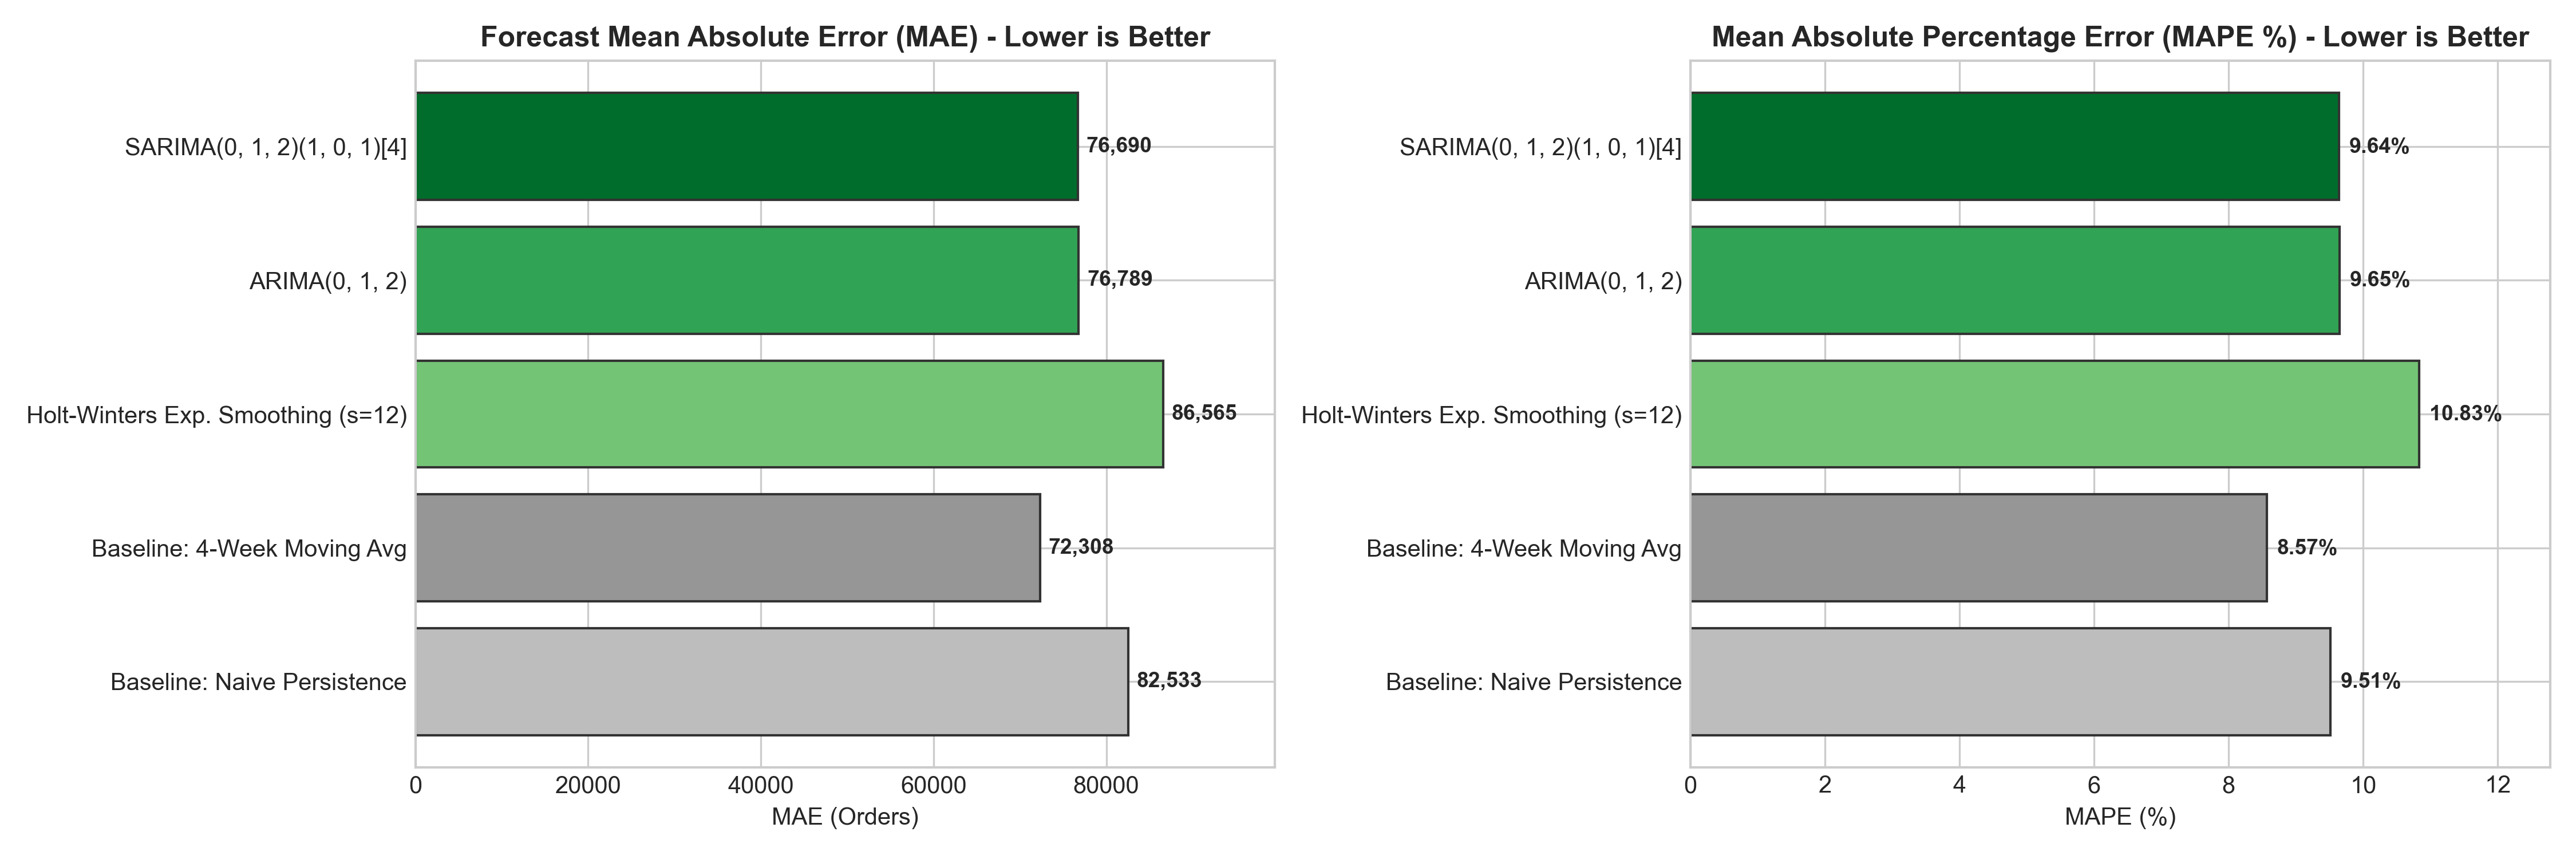

In [ ]:
summary_df = pd.DataFrame(results)
display(summary_df)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
colors = ['#bdbdbd', '#969696', '#74c476', '#31a354', '#006d2c']

bars1 = ax1.barh(summary_df['Model'], summary_df['MAE'], color=colors, edgecolor='#333333')
ax1.set_title('Forecast Mean Absolute Error (MAE) - Lower is Better', fontsize=12, fontweight='bold')
ax1.set_xlabel('MAE (Orders)')
for b in bars1:
    w = b.get_width()
    ax1.text(w + 1000, b.get_y() + b.get_height()/2, f'{w:,.0f}', va='center', fontsize=9, fontweight='bold')
ax1.set_xlim(0, max(summary_df['MAE']) * 1.15)

bars2 = ax2.barh(summary_df['Model'], summary_df['MAPE_%'], color=colors, edgecolor='#333333')
ax2.set_title('Mean Absolute Percentage Error (MAPE %) - Lower is Better', fontsize=12, fontweight='bold')
ax2.set_xlabel('MAPE (%)')
for b in bars2:
    w = b.get_width()
    ax2.text(w + 0.15, b.get_y() + b.get_height()/2, f'{w:.2f}%', va='center', fontsize=9, fontweight='bold')
ax2.set_xlim(0, max(summary_df['MAPE_%']) * 1.18)

plt.tight_layout()
plt.show()

### 6. Out-of-Sample 25-Week Macro Forecast Trajectory
We project the 25-week forecast (Weeks 121–145) alongside historical data and 95% SARIMA prediction intervals.

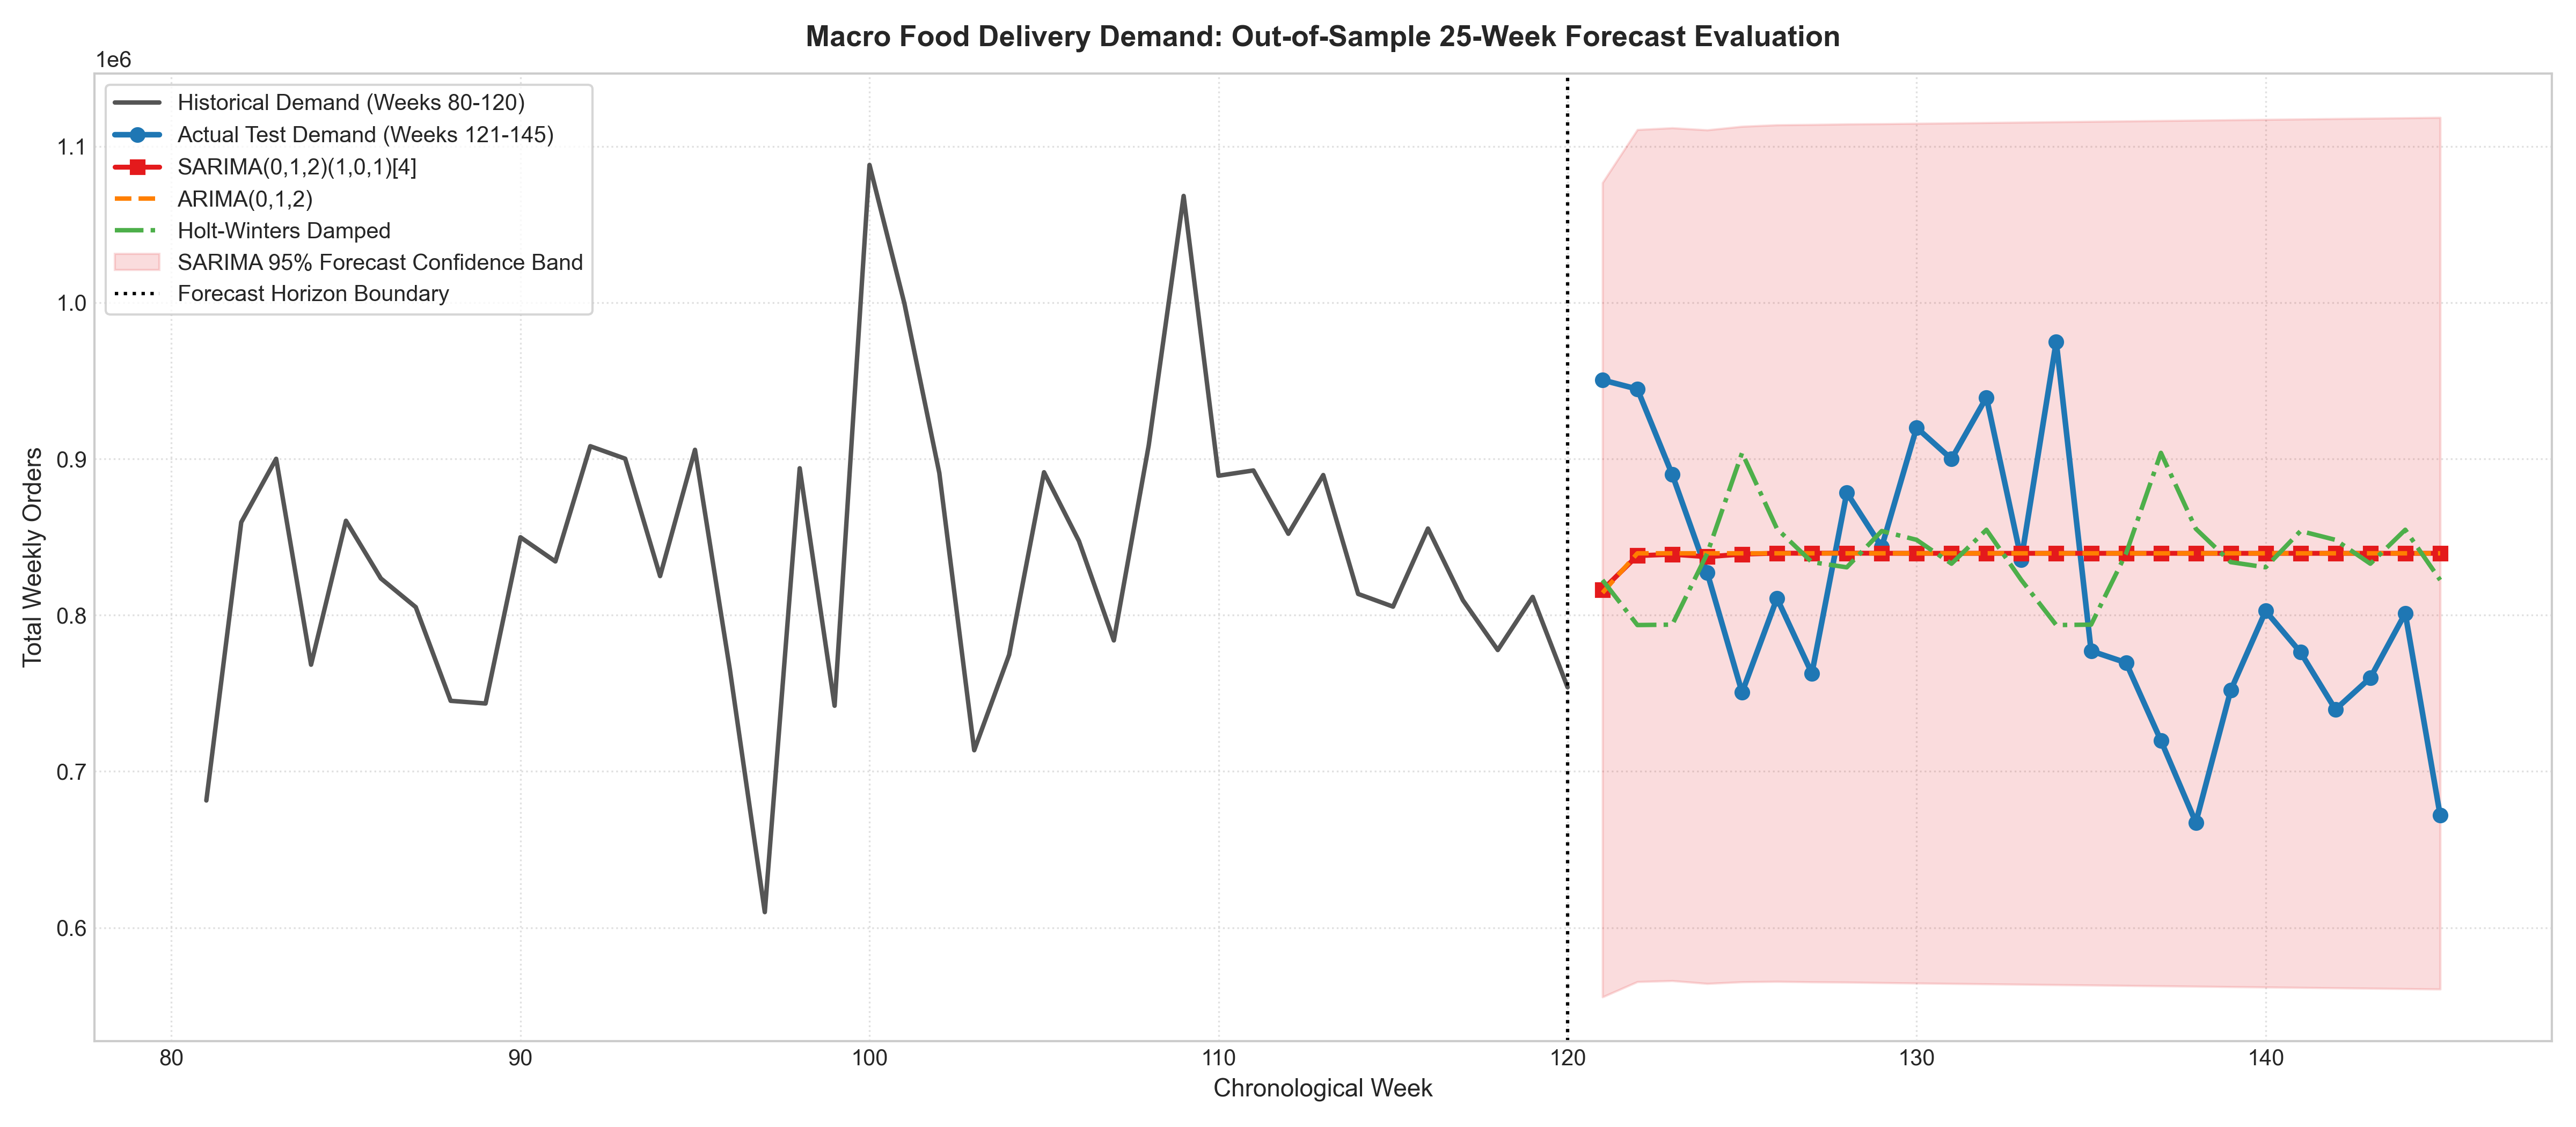

In [ ]:
sarima_forecast_res = sarima_model.get_forecast(steps=len(y_test))
ci = sarima_forecast_res.conf_int(alpha=0.05)
ci_lower = ci[:, 0] if isinstance(ci, np.ndarray) else ci.iloc[:, 0]
ci_upper = ci[:, 1] if isinstance(ci, np.ndarray) else ci.iloc[:, 1]

fig, ax = plt.subplots(figsize=(16, 7))

# Historical context (Weeks 80 to 120)
ax.plot(weeks_train[80:], y_train[80:], color='#555555', linewidth=2, label='Historical Demand (Weeks 80-120)')

# Actual test horizon
ax.plot(weeks_test, y_test, color='#1f77b4', marker='o', linewidth=2.5, label='Actual Test Demand (Weeks 121-145)')

# Model Forecasts
ax.plot(weeks_test, forecasts['SARIMA(0, 1, 2)(1, 0, 1)[4]'], color='#e41a1c', marker='s', linewidth=2.2, linestyle='-', label='SARIMA(0,1,2)(1,0,1)[4]')
ax.plot(weeks_test, forecasts['ARIMA(0, 1, 2)'], color='#ff7f00', linewidth=2, linestyle='--', label='ARIMA(0,1,2)')
ax.plot(weeks_test, forecasts['Holt-Winters Exp. Smoothing (s=12)'], color='#4daf4a', linewidth=2, linestyle='-.', label='Holt-Winters Damped')

# Prediction Interval
ax.fill_between(weeks_test, ci_lower, ci_upper, color='#e41a1c', alpha=0.15, label='SARIMA 95% Forecast Confidence Band')

ax.axvline(120, color='black', linestyle=':', linewidth=1.5, label='Forecast Horizon Boundary')
ax.set_title('Macro Food Delivery Demand: Out-of-Sample 25-Week Forecast Evaluation', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Chronological Week', fontsize=11)
ax.set_ylabel('Total Weekly Orders', fontsize=11)
ax.legend(loc='upper left', fontsize=10, frameon=True)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 7. Micro-Level SKU Inventory Forecasting: Meal 2290 (Rice Bowl)
To demonstrate hierarchical demand forecasting (macro capacity planning vs micro procurement), we fit SARIMA on the single highest-volume menu item: **Meal 2290 (Rice Bowl - Indian cuisine)**.

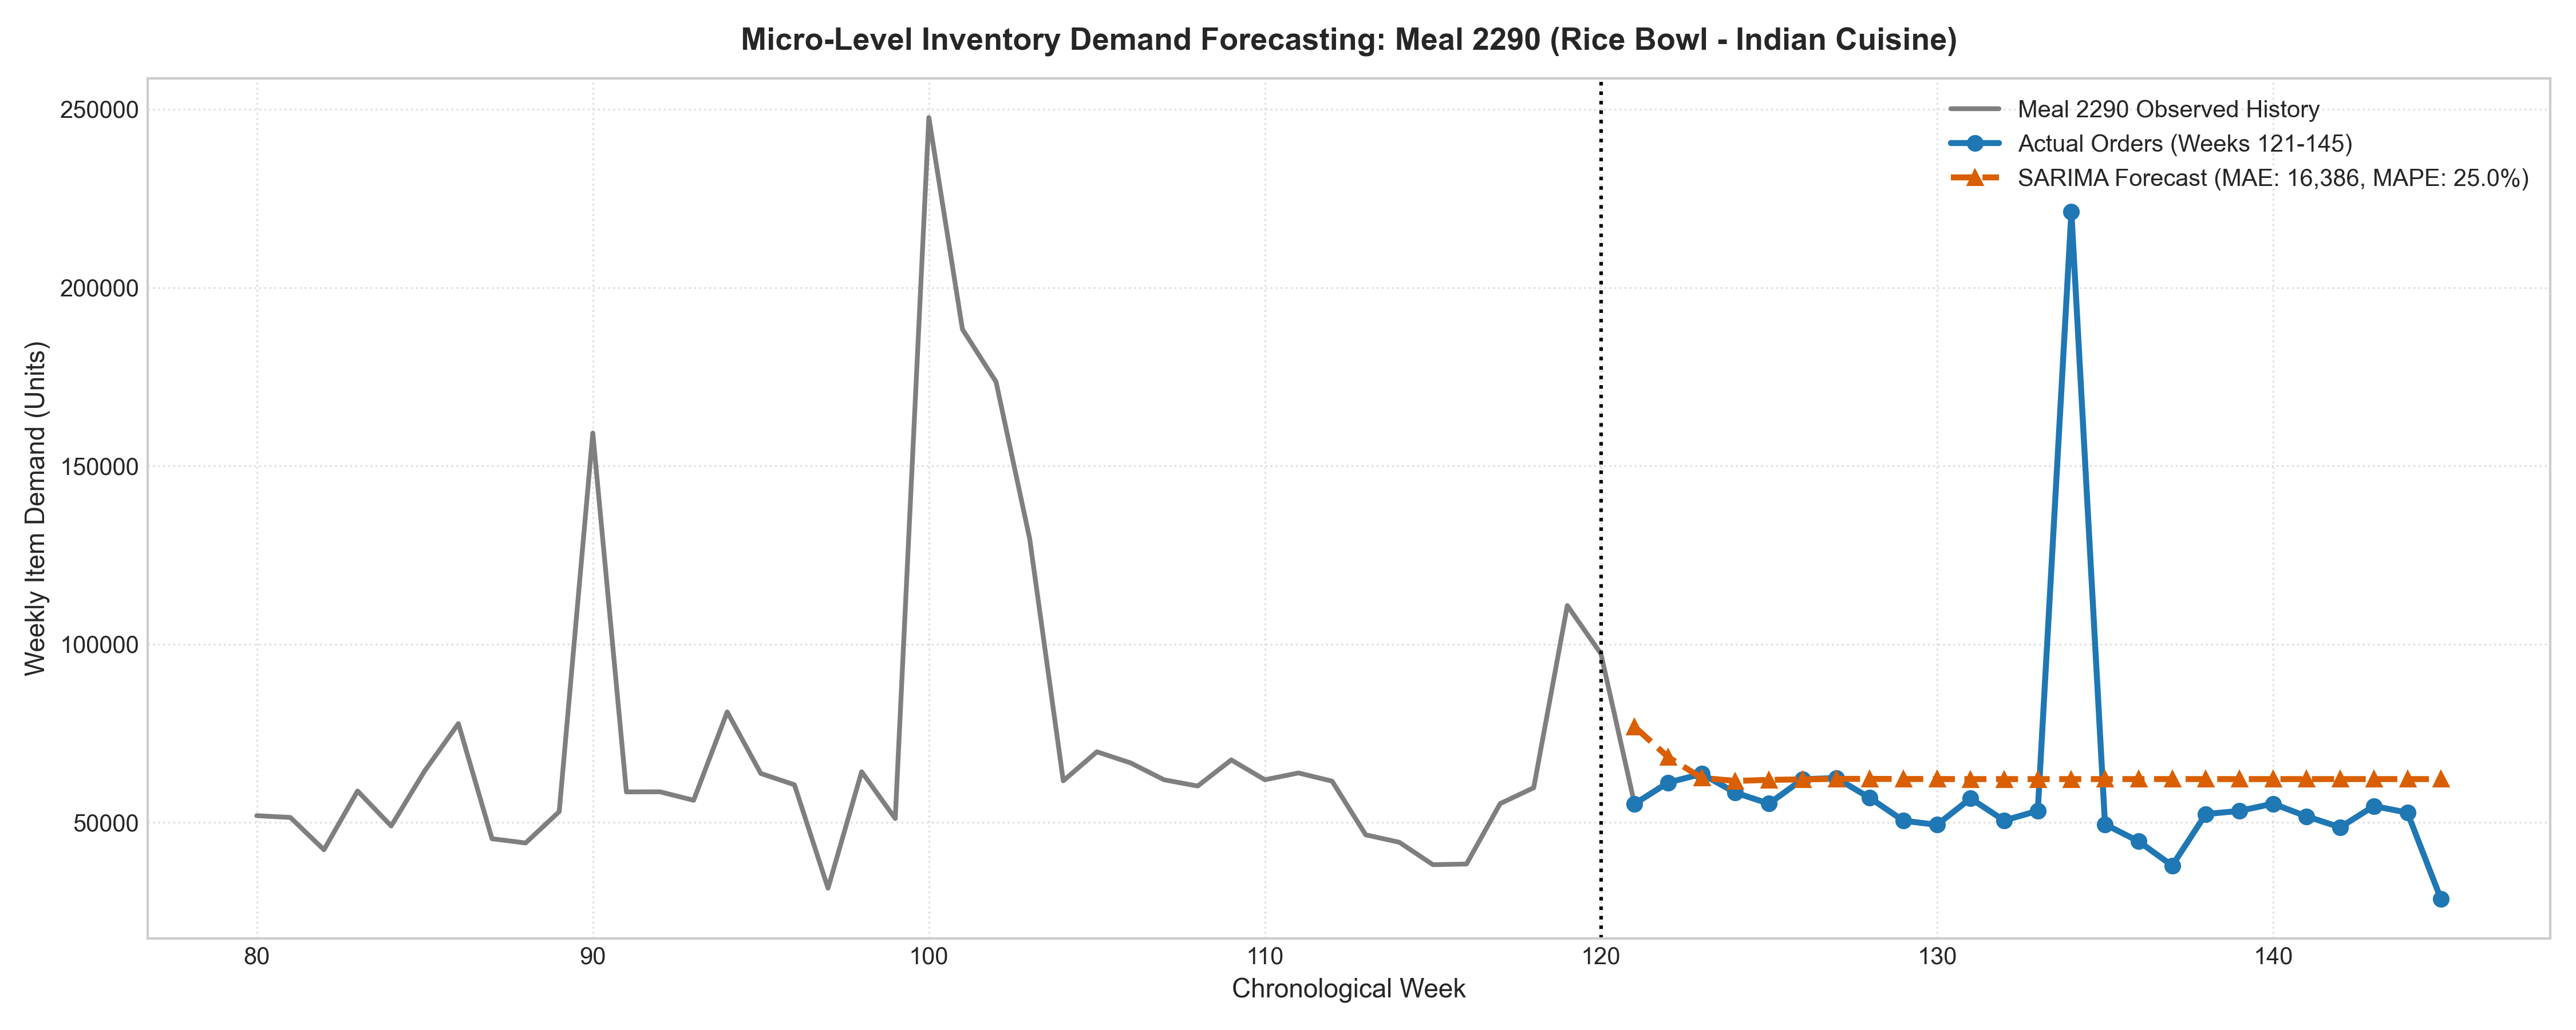

In [ ]:
meal_2290 = train[train['meal_id'] == 2290].groupby('week')['num_orders'].sum().reset_index()
y_m_train = meal_2290[meal_2290['week'] <= 120]['num_orders'].values
y_m_test  = meal_2290[meal_2290['week'] > 120]['num_orders'].values
w_m_test  = meal_2290[meal_2290['week'] > 120]['week'].values

m_sarima = SARIMAX(y_m_train, order=(1, 1, 1), seasonal_order=(1, 0, 0, 4), enforce_stationarity=False).fit(disp=False)
m_pred = m_sarima.forecast(len(y_m_test))
m_mae = mean_absolute_error(y_m_test, m_pred)
m_mape = np.mean(np.abs((y_m_test - m_pred) / y_m_test)) * 100

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(meal_2290[meal_2290['week'] >= 80]['week'], meal_2290[meal_2290['week'] >= 80]['num_orders'],
        color='#7f7f7f', linewidth=2, label='Meal 2290 Observed History')
ax.plot(w_m_test, y_m_test, color='#1f77b4', marker='o', linewidth=2.5, label='Actual Orders (Weeks 121-145)')
ax.plot(w_m_test, m_pred, color='#d95f02', marker='^', linewidth=2.5, linestyle='--', label=f'SARIMA Forecast (MAE: {m_mae:,.0f}, MAPE: {m_mape:.1f}%)')
ax.axvline(120, color='black', linestyle=':', linewidth=1.5)
ax.set_title('Micro-Level Inventory Demand Forecasting: Meal 2290 (Rice Bowl - Indian Cuisine)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Chronological Week', fontsize=11)
ax.set_ylabel('Weekly Item Demand (Units)', fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 8. Time Series Model Serialization
We serialize the trained macro SARIMA model and its seasonal decomposition artifacts into `models/best_macro_sarima.joblib` for operational loading.

In [ ]:
os.makedirs('models', exist_ok=True)
ts_artifacts = {
    'model': sarima_model,
    'model_name': 'SARIMA(0, 1, 2)(1, 0, 1)[4]',
    'train_weeks': (1, 120),
    'test_weeks': (121, 145),
    'metrics': res_sarima,
    'decomp': decomp
}
joblib.dump(ts_artifacts, 'models/best_macro_sarima.joblib')
print("Macro SARIMA model successfully serialized to models/best_macro_sarima.joblib")

Macro SARIMA model successfully serialized to models/best_macro_sarima.joblib
